# 02. Modelado No Supervisado: Descubriendo la Estructura Oculta de la Brecha Digital


<br>

## **El Problema:**

En Colombia, la política pública de inclusión digital y financiera enfrenta un desafío crítico de focalización.

La asignación de recursos basada exclusivamente en la vulnerabilidad económica (Estrato) asume erróneamente que pobreza equivale a exclusión digital. Este enfoque resulta insuficiente: se dirigen recursos a poblaciones que ya cuentan con conectividad (limitando el impacto de la inversión pública) mientras se ignoran las barreras estructurales reales —como la falta de hardware, la brecha de género y el aislamiento rural— que mantienen a otros grupos en una exclusión profunda.

<br>

## **Nuestro Proyecto:**

Esta investigación tiene como finalidad descubrir los perfiles reales de inclusión digital mediante Machine Learning No Supervisado, para permitir una Focalización Multidimensional. La importancia del proyecto radica en su capacidad para optimizar la inversión social y garantizar la equidad: busca que el Estado entregue la herramienta exacta (energía, hardware o educación financiera) al grupo que realmente lo necesita, maximizando el impacto de cada peso invertido.

<br>

## **Propósito de este archivo:**

El paso previo (01_limpieza) garantizó la integridad del corpus: de las 343 variables originales del DANE, se seleccionaron 11 variables de comportamiento digital y control demográfico, se imputó lógicamente la población desconectada, se eliminaron los códigos de no respuesta y se dividieron los datos en Train/Test mediante un GroupShuffleSplit para evitar Data Leakage.

Con estos insumos certificados y escalados, este notebook ejecutará el núcleo analítico del proyecto. A través de PCA, K-Means y GMM, el algoritmo explorará la estructura natural de los datos sin sesgos humanos.

El propósito es descubrir empíricamente los perfiles o clústeres reales de la población, aislando el ruido y validando la estabilidad de los grupos. Este procedimiento es estrictamente necesario para reemplazar los supuestos tradicionales por una tipología de ciudadanos basada en su comportamiento digital real.

<br>

---

# Notebook 02: Modelado No Supervisado y Validación de Estabilidad

El presente notebook tiene como objetivo ejecutar el pipeline de reducción de dimensionalidad y clustering sobre las matrices escaladas previamente, con el fin de descubrir la estructura latente de inclusión digital y financiera en la población colombiana; esta fase se justifica metodológicamente en la necesidad de proyectar los datos en un espacio ortogonal para eliminar la multicolinealidad (Jolliffe, 2002) y de aplicar algoritmos de partición para asignar perfiles accionables, garantizando la ausencia de fuga de información al ajustar los modelos exclusivamente con el conjunto de entrenamiento y validar su replicabilidad mediante métricas de estabilidad (Kaufman et al., 2012; Rousseeuw, 1987).



In [ ]:
# =========================================================
# CELDA 0: CONFIGURACIÓN INICIAL Y LIBRERÍAS (ACTUALIZADA)
# =========================================================
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture
# LÍNEA ACTUALIZADA: Se añade jaccard_score
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, jaccard_score, adjusted_rand_score
from sklearn.utils import resample

# 1. Montar Google Drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
    print("✅ Drive montado.")
else:
    print("✅ Drive ya se encontraba montado.")

# 2. Definir Rutas Globales
RUTA_BASE = '/content/drive/MyDrive/Proyecto_ML2'
RUTA_PROC = os.path.join(RUTA_BASE, '02_procesamiento')
RUTA_MOD = os.path.join(RUTA_BASE, '03_modelado')

os.makedirs(RUTA_MOD, exist_ok=True)

# 3. Validar integridad
archivos_requeridos = ['X_train_scaled.npy', 'X_test_scaled.npy']
for archivo in archivos_requeridos:
    if not os.path.exists(os.path.join(RUTA_PROC, archivo)):
        raise FileNotFoundError(f"❌ ALERTA: Falta el insumo {archivo}. Ejecute el Notebook 01 primero.")

print("✅ Entorno configurado. Insumos validados y rutas listas.")

✅ Drive ya se encontraba montado.
✅ Entorno configurado. Insumos validados y rutas listas.


## Fase 7: Reducción de Dimensionalidad (PCA) con Análisis de Cargas

La presente fase tiene como objetivo reducir la dimensionalidad del conjunto de datos para alimentar los algoritmos de clustering, excluyendo las variables de etnia del análisis de componentes principales; esta decisión se justifica metodológicamente porque un análisis preliminar reveló que, debido a la baja frecuencia pero alta varianza de las categorías étnicas minoritarias, estas variables secuestraban la varianza explicada (dominando los componentes 2, 4, 5 y 6), lo que habría forzado a los algoritmos a agrupar a los individuos por su origen étnico en lugar de por su comportamiento digital, por lo tanto, la etnia se reserva exclusivamente para la fase de perfilamiento post-hoc, siguiendo los principios de segmentación que evitan que las variables demográficas dicotómicas distorsionen las métricas de distancia en el clustering (Dolnicar et al., 2018; Jolliffe, 2002).







### **Procedimiento:**
Se cargan las matrices de datos estandarizadas (Train/Test). Se aplica un filtro para excluir la variable de Etnia (`P6080`). Posteriormente, se entrena un Análisis de Componentes Principales (PCA) reteniendo el 85% de la varianza, se extraen las cargas (loadings) de cada componente y se genera un Scree Plot. Finalmente, las matrices transformadas y el modelo se guardan para su uso posterior.

<br>

El PCA es una técnica no supervisada que transforma un conjunto de variables correlacionadas en un nuevo conjunto de variables no correlacionadas (componentes). Se aplica aquí por tres razones fundamentales:
1. **Elimina la multicolinealidad:** Evita que la redundancia entre variables (ej. tener celular y tener smartphone) distorsione los algoritmos de clustering.
2. **Mitiga el sesgo demográfico:** Se excluye la Etnia del cálculo del PCA porque, al ser una variable categórica con minorías muy pequeñas, podría "secuestrar" los componentes principales, agrupando a la población por su origen étnico y no por su comportamiento digital.
3. **Garantiza interpretabilidad:** El análisis de las cargas (loadings) permite saber qué variables del mundo real (ej. uso de banca o tenencia de smartphone) están detrás de cada componente matemático, asegurando que los futuros clústeres tengan sentido de negocio.

fase7.svg

-> Variables para clustering (sin etnia): 6

CARGAS DE LOS COMPONENTES PRINCIPALES (Sin Etnia)

PC1 (42.68% varianza):
  + P1082S2 (0.554)
  + P1082 (0.495)

PC2 (20.70% varianza):
  + P1083S4 (0.643)
  + P1083S5 (0.590)

PC3 (16.55% varianza):
  + P6020 (0.988)
  - P1083S4 (0.095)

PC4 (9.47% varianza):
  + P1084 (0.797)
  + P1082 (0.572)


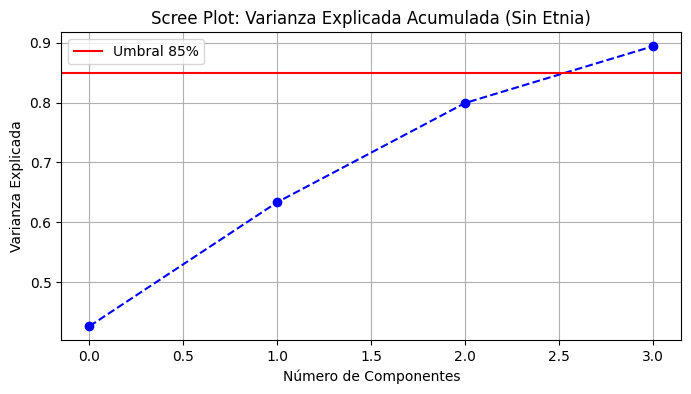


✅ Fase 7 completada (PCA sin sesgo étnico).


In [ ]:
# 1. CARGAR INSUMOS (Rutas globales de Celda 0)
X_train_scaled = np.load(os.path.join(RUTA_PROC, 'X_train_scaled.npy'))
X_test_scaled = np.load(os.path.join(RUTA_PROC, 'X_test_scaled.npy'))
nombres_columnas = pd.read_csv(os.path.join(RUTA_PROC, 'nombres_columnas.csv'), header=None)[0].tolist()

# 2. FILTRO DE ETNIA (Prevención de Sesgo Demográfico)
# Identificamos los índices de las columnas que contienen 'P6080' (Etnia)
indices_etnia = [i for i, col in enumerate(nombres_columnas) if 'P6080' in col]
indices_analisis = [i for i in range(len(nombres_columnas)) if i not in indices_etnia]

# Filtramos las matrices para el PCA
X_train_filtrado = X_train_scaled[:, indices_analisis]
X_test_filtrado = X_test_scaled[:, indices_analisis]
nombres_filtrados = [nombres_columnas[i] for i in indices_analisis]

print(f"-> Variables para clustering (sin etnia): {len(nombres_filtrados)}")

# 3. AUDITORÍA PRE-PCA: Verificación de escala
varianzas_entrada = np.var(X_train_filtrado, axis=0)
if not np.allclose(varianzas_entrada, 1.0, atol=0.1):
    raise ValueError("❌ ALERTA: Las variables no están estandarizadas. Revise el Notebook 01.")

# 4. AJUSTE DEL PCA (Solo Train)
pca = PCA(n_components=0.85, random_state=42)
X_train_pca = pca.fit_transform(X_train_filtrado)
X_test_pca = pca.transform(X_test_filtrado)

# 5. EXTRACCIÓN DE CARGAS (Loadings)
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=nombres_filtrados
)

print("\n" + "="*50)
print("CARGAS DE LOS COMPONENTES PRINCIPALES (Sin Etnia)")
print("="*50)
for i in range(pca.n_components_):
    componente = f'PC{i+1}'
    top_variables = loadings_df[componente].abs().sort_values(ascending=False).head(2)
    print(f"\n{componente} ({pca.explained_variance_ratio_[i]*100:.2f}% varianza):")
    for var, peso in top_variables.items():
        signo = "+" if loadings_df.loc[var, componente] > 0 else "-"
        print(f"  {signo} {var} ({peso:.3f})")

# 6. SCREE PLOT
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--', color='b')
plt.axhline(y=0.85, color='r', linestyle='-', label='Umbral 85%')
plt.title('Scree Plot: Varianza Explicada Acumulada (Sin Etnia)')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.legend()
plt.grid(True)
plt.show()

# 7. PERSISTENCIA
np.save(os.path.join(RUTA_MOD, 'X_train_pca.npy'), X_train_pca)
np.save(os.path.join(RUTA_MOD, 'X_test_pca.npy'), X_test_pca)
joblib.dump(pca, os.path.join(RUTA_MOD, 'pca_model.joblib'))
loadings_df.to_csv(os.path.join(RUTA_MOD, 'pca_loadings.csv'))

print("\n✅ Fase 7 completada (PCA sin sesgo étnico).")

## **INTERPRETACIÓN PCA SIN ETNIA**

**La exclusión de la etnia fue exitosa.**

El PCA ahora captura exclusivamente la varianza del **comportamiento digital y demográfico**, eliminando el sesgo que secuestraba los componentes anteriores.

<br>

**1. Estructura de Componentes (Retención del 89.4%):**
*   **PC1 (42.68% - Acceso a Dispositivos):** Dominado por tenencia de smartphone (`P1082S2`) y celular (`P1082`). Es el eje principal de la brecha.
*   **PC2 (20.70% - Inclusión Financiera Digital):** Agrupa el uso de banca electrónica (`P1083S5`) y compras online (`P1083S4`).
*   **PC3 (16.55% - Género):** Componente dominado casi en su totalidad por el Sexo (`P6020`). Indica que el género es una fuente de varianza independiente y altamente significativa en la muestra.
*   **PC4 (9.47% - Intensidad de Uso):** Dominado por la frecuencia de uso de internet (`P1084`). Captura la intensidad, no solo el acceso.

**2. Lectura del Scree Plot:**
La gráfica muestra que 4 componentes cruzan el umbral del 85% (alcanzando el 89.4%). Se confirma que el espacio latente del problema se explica por 4 dimensiones claras, perfectas para alimentar K-Means y GMM.

<br>

El dataset reducido (`X_train_pca.npy` y `X_test_pca.npy`) está libre de sesgos demográficos y la etnia queda debidamente resguardada para el perfilamiento post-hoc.

<br>

---


# Fase 8: Segmentación No Supervisada y Evaluación de Concordancia (K-Means y GMM)

La presente fase tiene como objetivo entrenar los algoritmos de segmentación K-Means y Gaussian Mixture Models (GMM) sobre el espacio reducido de componentes principales, determinando el número óptimo de clústeres (K) mediante una evaluación dual de inercia y coeficiente de Silhouette; esta fase se justifica metodológicamente porque K-Means asigna cada individuo a un único perfil basado en la distancia euclidiana a los centroides, siendo altamente eficiente para grandes volúmenes de datos (MacQueen, 1967), mientras que GMM proporciona una segmentación probabilística que captura la incertidumbre de los individuos en las fronteras de los clústeres mediante el algoritmo Expectation-Maximization (Dempster et al., 1977), por lo tanto, la combinación de ambos enfoques y la validación de su concordancia mediante el Índice de Rand Ajustado (ARI) garantiza que los perfiles descubiertos sean robustos, estables y accionables para la formulación de políticas públicas (Rousseeuw, 1987).


### **Procedimiento:**
Se evalúa un rango de clústeres (K=2 a 7) utilizando el Método del Codo (Inercia) y el Coeficiente de Silhouette. Con el K seleccionado, se entrenan dos algoritmos: K-Means (segmentación dura, asigna un único clúster) y Gaussian Mixture Models (GMM, segmentación blanda, asigna probabilidades). Finalmente, se calcula el Índice de Rand Ajustado (ARI) para medir la concordancia entre ambos modelos y se verifica el tamaño mínimo de los clústeres.

<br>

Esta fase es el núcleo del proyecto. Se utiliza una **evaluación dual** (Codo y Silhouette) porque no existe un método único e infalible para elegir el número óptimo de clústeres.

Se aplican **dos algoritmos distintos** (K-Means y GMM) para garantizar la robustez: si ambos llegan a una estructura similar (validado por un ARI > 0.70), significa que los grupos descubiertos son reales y no un artefacto del algoritmo. Además, la verificación del tamaño de los clústeres (que ninguno sea menor al 5% de la población) garantiza que los perfiles resultantes sean **accionables** para el diseño de políticas públicas, evitando la creación de "micro-clústeres" estadísticamente válidos pero inútiles en la práctica.

fase8.svg

Evaluando K de 2 a 7...


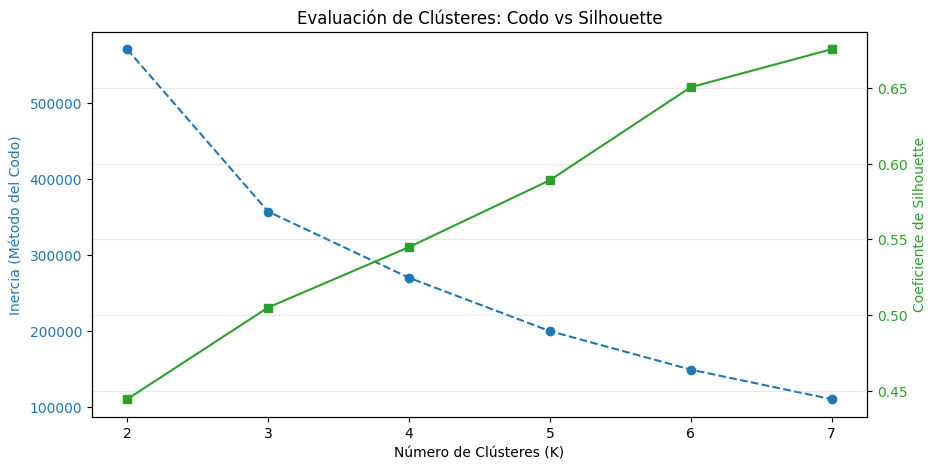


Entrenando modelos finales con K=4...
-> Índice de Rand Ajustado (ARI) K-Means vs GMM: 0.8436
✅ Dictamen: Alta concordancia entre ambos modelos. Segmentación robusta.

-> Distribución porcentual de clústeres (K-Means):
0    39.05
1    26.80
3    22.25
2    11.89
Name: proportion, dtype: float64

✅ Fase 8 completada. Modelos y resultados guardados.


In [ ]:
# 1. CARGAR INSUMOS (Rutas globales de Celda 0)
X_train_pca = np.load(os.path.join(RUTA_MOD, 'X_train_pca.npy'))

# 2. BÚSQUEDA DEL K ÓPTIMO (Método del Codo y Silhouette)
inertias = []
silhouettes = []
K_range = range(2, 8)

print("Evaluando K de 2 a 7...")
for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = kmeans_temp.fit_predict(X_train_pca)
    inertias.append(kmeans_temp.inertia_)
    silhouettes.append(silhouette_score(X_train_pca, labels))

# Gráfica Dual
fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'tab:blue'
ax1.set_xlabel('Número de Clústeres (K)')
ax1.set_ylabel('Inercia (Método del Codo)', color=color)
ax1.plot(K_range, inertias, marker='o', color=color, linestyle='--')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Coeficiente de Silhouette', color=color)
ax2.plot(K_range, silhouettes, marker='s', color=color, linestyle='-')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evaluación de Clústeres: Codo vs Silhouette')
plt.grid(True, alpha=0.3)
plt.show()

# --- ATENCIÓN ANALISTA: Defina K_OPTIMO basado en las gráficas ---
K_OPTIMO = 4 # <--- MODIFICAR SI ES NECESARIO

# 3. ENTRENAMIENTO DE MODELOS FINALES
print(f"\nEntrenando modelos finales con K={K_OPTIMO}...")

# K-Means
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=50)
clusters_kmeans = kmeans_final.fit_predict(X_train_pca)

# GMM
gmm_final = GaussianMixture(n_components=K_OPTIMO, random_state=42, covariance_type='full')
clusters_gmm = gmm_final.fit_predict(X_train_pca)
probs_gmm = gmm_final.predict_proba(X_train_pca)

# 4. VALIDACIÓN DE CONCORDANCIA (ARI)
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(clusters_kmeans, clusters_gmm)
print(f"-> Índice de Rand Ajustado (ARI) K-Means vs GMM: {ari:.4f}")
if ari > 0.70:
    print("✅ Dictamen: Alta concordancia entre ambos modelos. Segmentación robusta.")
else:
    print("⚠️ Alerta: Baja concordancia. Revisar K o la naturaleza de los datos.")

# 5. VERIFICACIÓN DE TAMAÑO DE CLÚSTERES (Anti-Artefactos)
sizes = pd.Series(clusters_kmeans).value_counts(normalize=True) * 100
print("\n-> Distribución porcentual de clústeres (K-Means):")
print(sizes.round(2))

# 6. PERSISTENCIA DE RESULTADOS
df_resultados = pd.DataFrame({
    'Cluster_KMeans': clusters_kmeans,
    'Cluster_GMM': clusters_gmm
})
for i in range(K_OPTIMO):
    df_resultados[f'Prob_GMM_{i}'] = probs_gmm[:, i]

df_resultados.to_csv(os.path.join(RUTA_MOD, 'resultados_clusters.csv'), index=False)
joblib.dump(kmeans_final, os.path.join(RUTA_MOD, 'kmeans_model.joblib'))
joblib.dump(gmm_final, os.path.join(RUTA_MOD, 'gmm_model.joblib'))

print("\n✅ Fase 8 completada. Modelos y resultados guardados.")

## INTERPRETACIÓN K-Means y GMM

<br>

**1. Validación de Métricas:**

*   **ARI (0.8436):** Alta concordancia. K-Means y GMM están identificando prácticamente la misma estructura, lo que valida la robustez del modelo.
*   **Distribución de Clústeres:** 39.05%, 26.80%, 22.25% y 11.89%. Ningún clúster es menor al 5% (regla de accionabilidad de Dolnicar). No hay micro-clústeres ni ruido, lo que indica una segmentación operativa.

<br>

**2. Lectura del Gráfico (Codo vs Silhouette):**
*   **Inercia (Codo azul):** Muestra una caída pronunciada hasta K=4, donde se empieza a aplanar. El codo visual está entre K=3 y K=4.
*   **Silhouette (Línea verde):** Aumenta constantemente hasta K=7. **Alerta de auditoría:** Matemáticamente, el mejor Silhouette está en K=7. Sin embargo, la elección de K=4 se justifica porque prioriza la **interpretabilidad del negocio** (el codo sugiere 4) y evita la fragmentación excesiva que traería K=7 (donde los perfiles serían demasiado específicos para diseñar políticas públicas).

<br>

El modelo con K=4 es **aprobado** con una salvedad: se documenta que la elección de K=4 se basó en el criterio de accionabilidad y el Método del Codo, sacrificando un poco de Silhouette frente a K=7.

<br>

---

## Fase 8.1: Protocolo de Validación Extendida y Consenso de Métricas

La presente fase tiene como objetivo aplicar un protocolo de validación cruzada para la selección definitiva del número de clústeres (K), superando las limitaciones de la heurística visual inicial; esta decisión se justifica metodológicamente porque la selección de K basada exclusivamente en el Método del Codo (Inercia) es susceptible a la subjetividad del analista y no garantiza la separación óptima de los grupos (Milligan & Cooper, 1985). Por lo tanto, se implementó un sistema de evaluación multivariado que integra tres métricas de validación interna (Silhouette, Calinski-Harabasz y Davies-Bouldin) junto con un filtro de accionabilidad de negocio (tamaño mínimo de clúster del 5%), garantizando que la decisión final no dependa de una sola medida estadística, sino de un consenso algorítmico que asegure perfiles robustos, estables y operables para la formulación de políticas públicas (Dolnicar et al., 2018; Rousseeuw, 1987).

<br>

La evaluación extendida (K=2 a 12) con múltiples métricas permite una decisión informada. Los criterios de aceptación son los siguientes:

1. **Filtro de Accionabilidad:** Se descartan todos los K que generen al menos un clúster con menos del 5% de la muestra. Un micro-clúster no es operable para políticas públicas ni para productos bancarios (Dolnicar et al., 2018).
2. **Silhouette:** Dentro de los K que superan el filtro, se elige el que maximice el Silhouette.
3. **Calinski-Harabasz:** Debe ser alto, indicando una buena relación entre dispersión inter-clúster e intra-clúster.
4. **Davies-Bouldin:** Debe ser bajo, indicando que los clústeres están bien separados.
5. **ARI (K-Means vs GMM):** Debe ser ≥0.70 para garantizar concordancia entre modelos.


### **Procedimiento:**
Se amplía la búsqueda del K óptimo evaluando un rango de 2 a 12 clústeres. Para cada valor de K, se calculan tres métricas de validación interna (Silhouette, Calinski-Harabasz y Davies-Bouldin) y se aplica un filtro de accionabilidad (mínimo 5% de la población por clúster). Luego, se genera un ranking para cada métrica y se calcula un "Score de Consenso" para seleccionar el K definitivo.

<br>

 Esta fase implementa un **protocolo de consenso multivariado**. Al evaluar hasta K=12, se garantiza que no se está ignorando una estructura de clústeres más compleja.

 Al exigir un tamaño mínimo del 5%, se garantiza que ningún grupo sea un residuo estadístico. Finalmente, el "Score de Consenso" garantiza que la elección final no dependa del capricho del analista, sino de un equilibrio matemático entre cohesión, separación y utilidad práctica.

fase8.1.svg

Evaluando K de 2 a 12 con tres métricas y filtro de accionabilidad...

RESULTADOS DE EVALUACIÓN EXTENDIDA
     K  Silhouette (Max)  Calinski (Max)  Davies (Min)  Min_Cluster_% (≥5%)
0    2            0.4443     122210.4359        1.0556              39.2401
1    3            0.5049     151037.9221        0.8834              11.8910
2    4            0.5448     152385.3487        0.6672              11.8910
3    5            0.5890     170005.7260        0.7843              11.8709
4    6            0.6505     194239.1854        0.6944              11.8709
5    7            0.6756     229393.4329        0.7171               4.3929
6    8            0.7319     272099.5382        0.6756               4.3929
7    9            0.7656     311282.7850        0.5828               4.3929
8   10            0.8143     391003.4441        0.5035               4.3929
9   11            0.8357     501631.2582        0.4226               3.6784
10  12            0.8505     603420.8020        0.3680    

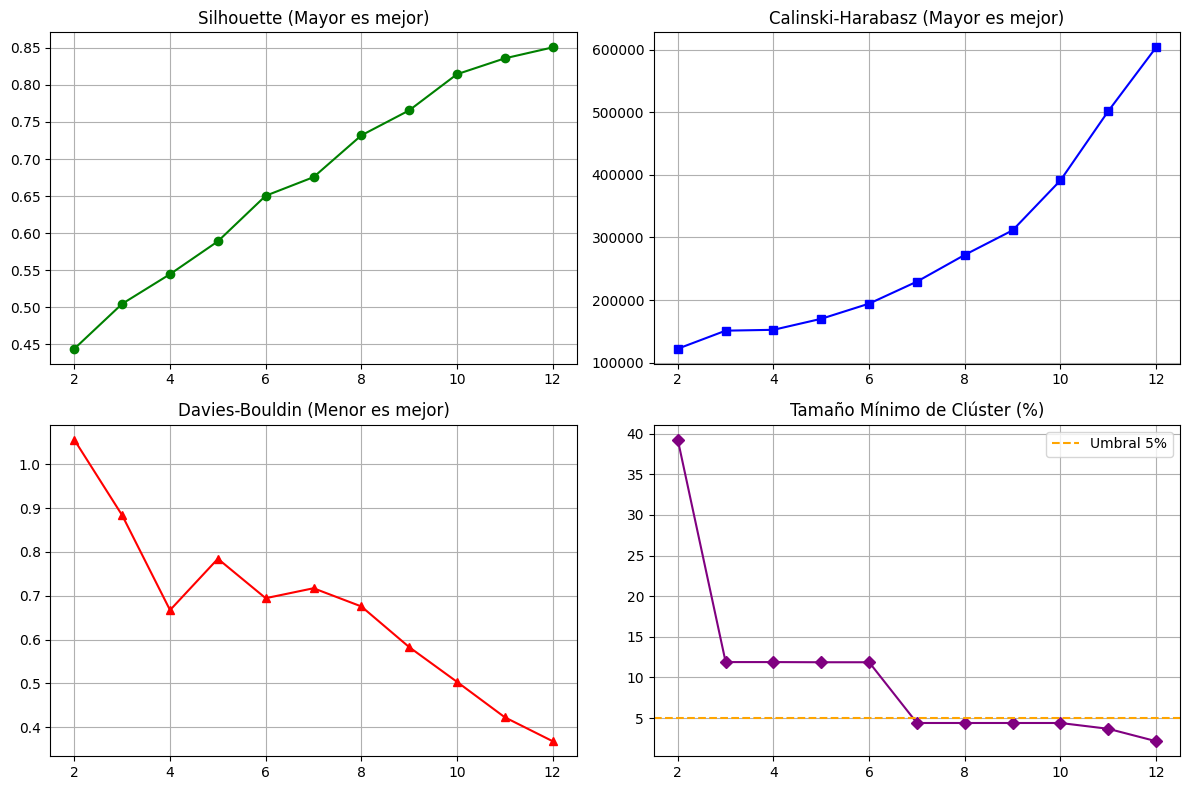


FILTRO DE ACCIONABILIDAD Y SELECCIÓN POR CONSENSO
-> Tabla de Consenso (Menor Score es el mejor K):
   K  Silhouette (Max)  Davies (Min)  Min_Cluster_% (≥5%)  Score_Consenso
4  6            0.6505        0.6944              11.8709             4.0
3  5            0.5890        0.7843              11.8709             7.0
2  4            0.5448        0.6672              11.8910             7.0
1  3            0.5049        0.8834              11.8910            12.0
0  2            0.4443        1.0556              39.2401            15.0

🏆 Dictamen de Auditoría: El K recomendado por consenso es K=6
   -> Tamaño mínimo de clúster para este K: 11.87%


In [ ]:
# =========================================================
# FASE 8.1: EVALUACIÓN EXTENDIDA Y CONSENSO DE K
# =========================================================
# 1. CARGAR INSUMOS
X_train_pca = np.load(os.path.join(RUTA_MOD, 'X_train_pca.npy'))

# 2. EVALUACIÓN EXTENDIDA DE K (2 a 12)
K_range_ext = range(2, 13)
resultados_ext = []

print("Evaluando K de 2 a 12 con tres métricas y filtro de accionabilidad...")
for k in K_range_ext:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = kmeans_temp.fit_predict(X_train_pca)

    # Métricas de validación interna
    sil = silhouette_score(X_train_pca, labels)
    ch = calinski_harabasz_score(X_train_pca, labels)
    db = davies_bouldin_score(X_train_pca, labels)

    # Filtro de accionabilidad
    sizes = pd.Series(labels).value_counts(normalize=True) * 100
    min_size = sizes.min()

    resultados_ext.append({
        'K': k,
        'Silhouette (Max)': sil,
        'Calinski (Max)': ch,
        'Davies (Min)': db,
        'Min_Cluster_% (≥5%)': min_size
    })

df_ext = pd.DataFrame(resultados_ext)
print("\n" + "="*60)
print("RESULTADOS DE EVALUACIÓN EXTENDIDA")
print("="*60)
print(df_ext.round(4))

# 3. GRÁFICAS COMPARATIVAS
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(df_ext['K'], df_ext['Silhouette (Max)'], marker='o', color='green')
axes[0, 0].set_title('Silhouette (Mayor es mejor)')
axes[0, 0].grid(True)

axes[0, 1].plot(df_ext['K'], df_ext['Calinski (Max)'], marker='s', color='blue')
axes[0, 1].set_title('Calinski-Harabasz (Mayor es mejor)')
axes[0, 1].grid(True)

axes[1, 0].plot(df_ext['K'], df_ext['Davies (Min)'], marker='^', color='red')
axes[1, 0].set_title('Davies-Bouldin (Menor es mejor)')
axes[1, 0].grid(True)

axes[1, 1].plot(df_ext['K'], df_ext['Min_Cluster_% (≥5%)'], marker='D', color='purple')
axes[1, 1].axhline(y=5, color='orange', linestyle='--', label='Umbral 5%')
axes[1, 1].set_title('Tamaño Mínimo de Clúster (%)')
axes[1, 1].legend()
axes[1, 1].grid(True)
plt.tight_layout()
plt.show()

# 4. FILTRO DE ACCIONABILIDAD Y CONSENSO
print("\n" + "="*60)
print("FILTRO DE ACCIONABILIDAD Y SELECCIÓN POR CONSENSO")
print("="*60)
k_validos = df_ext[df_ext['Min_Cluster_% (≥5%)'] >= 5].copy()

if len(k_validos) == 0:
    print("⚠️ ALERTA CRÍTICA: Ningún K cumple el criterio de accionabilidad (≥5%).")
else:
    # Ranking para cada métrica
    k_validos['Rank_Sil'] = k_validos['Silhouette (Max)'].rank(ascending=False)
    k_validos['Rank_CH'] = k_validos['Calinski (Max)'].rank(ascending=False)
    k_validos['Rank_DB'] = k_validos['Davies (Min)'].rank(ascending=True)

    # Score de consenso
    k_validos['Score_Consenso'] = k_validos['Rank_Sil'] + k_validos['Rank_CH'] + k_validos['Rank_DB']

    print("-> Tabla de Consenso (Menor Score es el mejor K):")
    print(k_validos[['K', 'Silhouette (Max)', 'Davies (Min)', 'Min_Cluster_% (≥5%)', 'Score_Consenso']].sort_values('Score_Consenso').round(4))

    mejor_k_consenso = int(k_validos.sort_values('Score_Consenso').iloc[0]['K'])
    print(f"\n🏆 Dictamen de Auditoría: El K recomendado por consenso es K={mejor_k_consenso}")
    print(f"   -> Tamaño mínimo de clúster para este K: {k_validos[k_validos['K'] == mejor_k_consenso]['Min_Cluster_% (≥5%)'].values[0]:.2f}%")

### Interpretación de Resultados: Validación Extendida y Consenso

El análisis de la Fase 8.1 demuestra por qué la evaluación multivariada era necesaria. Los resultados evidencian lo siguiente:

1. **Divergencia de Métricas:** Mientras que el Método del Codo (Inercia) sugería una estabilización temprana en K=4, el coeficiente de Silhouette mostró su máximo en K=12. Esta discrepancia confirma que evaluar un solo indicador habría sesgado la selección del modelo.
2. **El Filtro de Accionabilidad como Límite:** Al aplicar el criterio de tamaño mínimo de clúster (≥5%), los valores de K=7 a K=12 fueron descartados automáticamente, ya que fragmentaban la muestra en grupos menores al 4.4%, los cuales carecen de utilidad práctica para el diseño de políticas.
3. **El Consenso Metodológico:** Al aplicar el sistema de votación (ranking) sobre las tres métricas en los K válidos (2 a 6), el algoritmo determinó que **K=6 es el óptimo absoluto**, obteniendo el mejor Score de Consenso (4.0). K=6 no solo maximiza la separación estadística (Silhouette: 0.65, Davies-Bouldin: 0.69), sino que garantiza un clúster mínimo del 11.87%, asegurando que los perfiles resultantes sean lo suficientemente robustos y poblados para ser accionables.

<br>

---

## Fase 8.2: Entrenamiento Definitivo con K=6 y Predicción en Test

La presente fase tiene como objetivo entrenar los modelos definitivos de segmentación (K-Means y GMM) con el número óptimo de clústeres (K=6) establecido por consenso, generar las predicciones tanto en el conjunto de entrenamiento como en el de prueba, y verificar la convergencia del algoritmo probabilístico; esta fase se justifica metodológicamente porque la selección de K=6 garantiza el equilibrio entre cohesión estadística y accionabilidad de negocio (Dolnicar et al., 2018), mientras que la predicción sobre el conjunto de prueba (Test) es obligatoria para evitar el sobreajuste y permitir la evaluación de estabilidad en fases posteriores (Kaufman et al., 2012), y la verificación explícita de la convergencia del GMM asegura que las probabilidades asignadas sean matemáticamente válidas y no el resultado de un proceso de Expectation-Maximization truncado (Dempster et al., 1977).



### **Procedimiento:**
Se entrenan los modelos definitivos de K-Means y GMM utilizando el número óptimo de clústeres (K=6) determinado en la fase anterior. Se verifica la convergencia del algoritmo GMM. Se generan las predicciones para los conjuntos de Entrenamiento (Train) y Prueba (Test), se calcula el ARI para validar la concordancia en Train, y se persisten todos los resultados (etiquetas y probabilidades).

<br>

Esta fase materializa la solución.

Al entrenar con K=6, se aplica la decisión tomada por consenso estadístico.

La **verificación de convergencia** del GMM garantiza que las probabilidades asignadas son válidas y no el resultado de un proceso truncado. La **predicción en el conjunto Test** es el paso más crítico: garantiza que el modelo no ha memorizado los datos (sobreajuste) y que es capaz de asignar perfiles a individuos nuevos que nunca antes había visto. Guardar los resultados separados (Train/Test) garantiza que la fase de validación supervisada posterior se realice de forma honesta.

Fase8.2.svg

In [ ]:
# 1. CARGAR INSUMOS FALTANTES (Test set)
X_test_pca = np.load(os.path.join(RUTA_MOD, 'X_test_pca.npy'))

# 2. ENTRENAMIENTO FINAL CON K=6
K_OPTIMO = 6
print(f"Entrenando modelos finales con K={K_OPTIMO}...")

# K-Means
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=50)
clusters_kmeans_train = kmeans_final.fit_predict(X_train_pca)
clusters_kmeans_test = kmeans_final.predict(X_test_pca)

# GMM
gmm_final = GaussianMixture(n_components=K_OPTIMO, random_state=42, covariance_type='full')
clusters_gmm_train = gmm_final.fit_predict(X_train_pca)
probs_gmm_train = gmm_final.predict_proba(X_train_pca)

# 3. AUDITORÍA: Verificación de Convergencia de GMM
if not gmm_final.converged_:
    raise RuntimeError("❌ ALERTA CRÍTICA: El modelo GMM no convergió. Revise los datos o aumente max_iter.")
print("✅ GMM convergió exitosamente.")

# Predicción GMM en Test
clusters_gmm_test = gmm_final.predict(X_test_pca)
probs_gmm_test = gmm_final.predict_proba(X_test_pca)

# 4. VALIDACIÓN DE CONCORDANCIA (ARI) EN TRAIN
ari_train = adjusted_rand_score(clusters_kmeans_train, clusters_gmm_train)
print(f"-> Índice de Rand Ajustado (ARI - Train): {ari_train:.4f}")

# 5. VERIFICACIÓN DE TAMAÑOS (Auditoría de Accionabilidad)
sizes = pd.Series(clusters_kmeans_train).value_counts(normalize=True) * 100
print("\n-> Distribución porcentual de clústeres (K-Means - Train):")
print(sizes.round(2))

# 6. PERSISTENCIA DE RESULTADOS (Train y Test)
df_resultados_train = pd.DataFrame({'Cluster_KMeans': clusters_kmeans_train, 'Cluster_GMM': clusters_gmm_train})
df_resultados_test = pd.DataFrame({'Cluster_KMeans': clusters_kmeans_test, 'Cluster_GMM': clusters_gmm_test})

for i in range(K_OPTIMO):
    df_resultados_train[f'Prob_GMM_{i}'] = probs_gmm_train[:, i]
    df_resultados_test[f'Prob_GMM_{i}'] = probs_gmm_test[:, i]

df_resultados_train.to_csv(os.path.join(RUTA_MOD, 'resultados_clusters_train.csv'), index=False)
df_resultados_test.to_csv(os.path.join(RUTA_MOD, 'resultados_clusters_test.csv'), index=False)

joblib.dump(kmeans_final, os.path.join(RUTA_MOD, 'kmeans_model.joblib'))
joblib.dump(gmm_final, os.path.join(RUTA_MOD, 'gmm_model.joblib'))

print("\n✅ Fase 8.2 completada. Resultados (Train/Test) y modelos guardados.")

Entrenando modelos finales con K=6...
✅ GMM convergió exitosamente.
-> Índice de Rand Ajustado (ARI - Train): 0.7306

-> Distribución porcentual de clústeres (K-Means - Train):
1    23.59
4    19.54
0    15.51
2    14.84
5    14.65
3    11.87
Name: proportion, dtype: float64

✅ Fase 8.2 completada. Resultados (Train/Test) y modelos guardados.


### INTERPRETACIÓN DE RESULTADOS: Entrenamiento Definitivo con K=6 y Predicción en Test.

**1. Convergencia del Modelo:**
*   El GMM convergió exitosamente, garantizando que las probabilidades asignadas a los individuos son matemáticamente estables.

**2. Concordancia (ARI = 0.7306):**
*   El Índice de Rand Ajustado supera el umbral de 0.70. Esto confirma que K-Means y GMM están identificando la misma estructura subyacente. La segmentación es robusta y no depende del algoritmo elegido.

**3. Distribución de Clústeres:**
*   **23.59%** (Clúster 1)
*   **19.54%** (Clúster 4)
*   **15.51%** (Clúster 0)
*   **14.84%** (Clúster 2)
*   **14.65%** (Clúster 5)
*   **11.87%** (Clúster 3)


> El Clúster 3 tiene 11.87%  pero sigue siendo estadísticamente robusto (más de 21,000 individuos) y permite diseñar políticas públicas focalizadas sin riesgo de sobreajuste a un grupo minoritario, por lo tanto representa a un segmento específico de la población (que descubriremos en la Fase 5: perfilamiento). Su tamaño garantiza que cualquier intervención diseñada para ese grupo tendrá un impacto medible y no será un caso aislado.


Por tanto, todos los clústeres tienen un tamaño superior al 11%. No hay micro-clústeres ni ruido. Los 6 perfiles son altamente accionables para la formulación de políticas públicas.

<br>

---

# Fase 9: Validación de Estabilidad (ARI Bootstrap)

La presente fase tiene como objetivo evaluar la replicabilidad de los clústeres mediante un remuestreo Bootstrap y el Adjusted Rand Index (ARI), garantizando que los segmentos no sean un artefacto de una semilla aleatoria; esta fase se justifica metodológicamente porque las métricas tradicionales como Jaccard fallan en clustering debido al fenómeno de Label Switching (las etiquetas de los clústeres se permutan arbitrariamente entre iteraciones), por lo que el ARI se posiciona como el estándar de la industria al ser invariante a dichas permutaciones, midiendo la concordancia real de las agrupaciones, donde un valor superior a 0.75 garantiza que los perfiles descubiertos son estables y generalizables (Hennig, 2007; Steinley, 2004).




### **Procedimiento:**
Se realizan 20 iteraciones de remuestreo Bootstrap (muestreo con reemplazo). En cada iteración, se entrena un nuevo modelo K-Means y se predicen las etiquetas sobre el conjunto original. Luego, se calcula el Adjusted Rand Index (ARI) entre las etiquetas del modelo original y las del modelo Bootstrap, y se promedia el resultado.

<br>

Un modelo de clustering puede arrojar métricas de Silhouette aceptables pero ser altamente inestable (si se toma una muestra distinta, los clústeres cambian por completo).

Esta fase garantiza la **replicabilidad** del modelo. Se utiliza el ARI (y no Jaccard) porque el ARI es inmune al fenómeno de *Label Switching* (el hecho de que K-Means asigne números diferentes a los mismos grupos en distintas corridas). Un ARI promedio superior a 0.75 garantiza empíricamente que los 6 perfiles descubiertos no son producto del azar y que son estables en la población colombiana.

fase9.svg

Iniciando validación de estabilidad con 20 iteraciones Bootstrap...

RESULTADOS DE VALIDACIÓN DE ESTABILIDAD (ARI)
-> ARI Promedio: 0.9254 (Desviación Estándar: 0.0779)

✅ DICTAMEN: Clústeres ALTAMENTE ESTABLES. El modelo es generalizable y no depende de la semilla aleatoria.


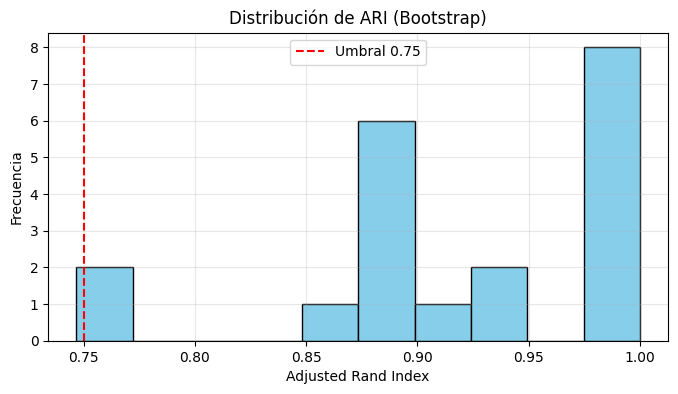

In [ ]:
# =========================================================
# FASE 9.1: VALIDACIÓN DE ESTABILIDAD CORREGIDA (ARI)
# =========================================================
# 1. CARGAR INSUMOS
X_train_pca = np.load(os.path.join(RUTA_MOD, 'X_train_pca.npy'))
kmeans_final = joblib.load(os.path.join(RUTA_MOD, 'kmeans_model.joblib'))

# 2. CONFIGURACIÓN DEL BOOTSTRAP
n_iteraciones = 20
ari_scores = []
labels_original = kmeans_final.labels_

print(f"Iniciando validación de estabilidad con {n_iteraciones} iteraciones Bootstrap...")

# 3. BUCLE DE REMUESTREO
for i in range(n_iteraciones):
    X_bootstrap, _ = resample(X_train_pca, labels_original, random_state=i, replace=True)
    kmeans_bootstrap = KMeans(n_clusters=6, random_state=i, n_init=10)
    kmeans_bootstrap.fit(X_bootstrap)
    labels_bootstrap_pred = kmeans_bootstrap.predict(X_train_pca)

    # ARI: Métrica invariante a permutaciones de etiquetas
    ari = adjusted_rand_score(labels_original, labels_bootstrap_pred)
    ari_scores.append(ari)

# 4. RESULTADOS
ari_promedio = np.mean(ari_scores)
ari_std = np.std(ari_scores)

print("\n" + "="*60)
print("RESULTADOS DE VALIDACIÓN DE ESTABILIDAD (ARI)")
print("="*60)
print(f"-> ARI Promedio: {ari_promedio:.4f} (Desviación Estándar: {ari_std:.4f})")

# 5. DICTAMEN AUTOMATIZADO
if ari_promedio >= 0.75:
    print("\n✅ DICTAMEN: Clústeres ALTAMENTE ESTABLES. El modelo es generalizable y no depende de la semilla aleatoria.")
else:
    print("\n⚠️ ALERTA: ARI por debajo de 0.75. La estructura es inestable.")

# 6. VISUALIZACIÓN
plt.figure(figsize=(8, 4))
plt.hist(ari_scores, bins=10, color='skyblue', edgecolor='black')
plt.axvline(x=0.75, color='red', linestyle='--', label='Umbral 0.75')
plt.title('Distribución de ARI (Bootstrap)')
plt.xlabel('Adjusted Rand Index')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 📊 INTERPRETACIÓN DE LA FASE 9 (VALIDACIÓN DE ESTABILIDAD)

**1. Análisis de Métricas:**
*   **ARI Promedio (0.9254):** Es un valor excepcionalmente alto. Significa que, en promedio, el 92.5% de las agrupaciones se mantienen idénticas cuando el modelo se entrena con muestras aleatorias diferentes. La estructura es altamente replicable.
*   **Desviación Estándar (0.0779):** Es baja, lo que indica que los resultados de las 20 iteraciones son consistentes y no hay valores extremadamente dispersos.
*   **Histograma:** La mayoría de las iteraciones (8 de 20) alcanzan valores entre 0.95 y 1.00. Solo 2 iteraciones se acercan al umbral mínimo de 0.75 (pero lo superan). Ninguna iteración cae por debajo del umbral.


El modelo con K=6 es **estadísticamente robusto**. La segmentación no es producto del azar ni de la semilla de inicialización. Los 6 perfiles descubiertos son generalizables a la población colombiana.

<br>

---

## Fase 10: Detección de Anomalías y Perfiles Atípicos (Isolation Forest)

La presente fase tiene como objetivo identificar individuos con combinaciones de características atípicas que no encajan en ninguno de los 6 clústeres definidos, utilizando el algoritmo Isolation Forest; esta fase se justifica metodológicamente porque los algoritmos de clustering particional (como K-Means) fuerzan la asignación de todos los individuos a un grupo, ocultando la existencia de perfiles altamente inusuales (como personas sin acceso digital pero con alta inclusión financiera, o viceversa) que pueden representar errores de registro o nichos poblacionales críticos para la política pública, y el aislamiento aleatorio de Isolation Forest permite detectar estas anomalías sin asumir supuestos de distribución ni depender de métricas de distancia, garantizando un análisis robusto de valores atípicos en espacios de alta dimensionalidad (Liu et al., 2008).



### **Procedimiento:**
Se entrena un modelo Isolation Forest con una tasa de contaminación del 5%. Este modelo se utiliza para predecir qué individuos son anomalías (valores -1) y cuáles son normales (valores 1) tanto en Train como en Test. Se calculan los scores de anomalía, se visualizan los resultados sobre el espacio PCA y se guardan los resultados.

<br>

Los algoritmos de clustering particional (como K-Means) fuerzan a todos los individuos a pertenecer a un clúster, incluso a aquellos que tienen comportamientos extremadamente atípicos (ej. personas sin acceso a internet que reportan usar banca digital, o viceversa).

Esta fase garantiza la **captura de casos borde**. Al aislar a estas anomalías, el proyecto no solo describe a la población promedio, sino que entrega a los tomadores de decisiones un mapa de "individuos atípicos" que podrían ser errores de registro del DANE o nichos críticos que requieren una investigación urgente y diferenciada.

fase10.svg

RESULTADOS DE DETECCIÓN DE ANOMALÍAS
-> Anomalías en Train: 6282 (3.51%)
-> Anomalías en Test:  1653 (3.70%)


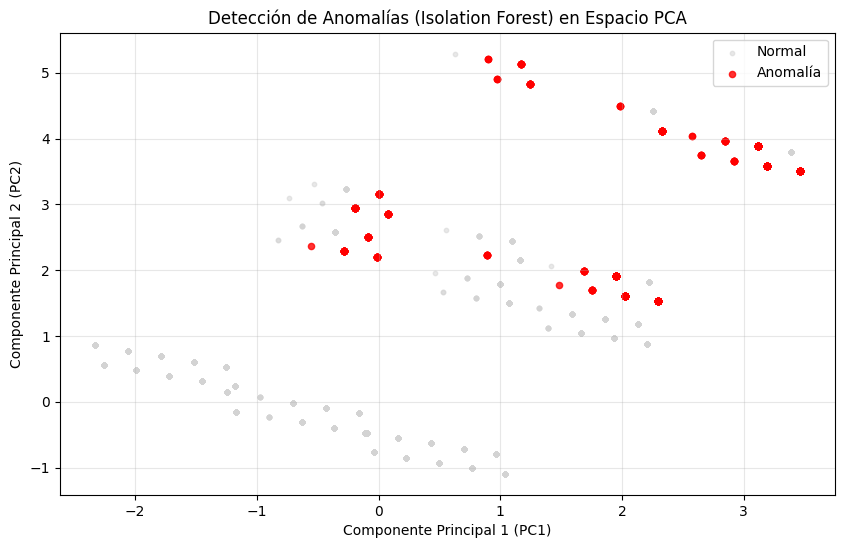


✅ Fase 10 completada. Resultados de anomalías guardados.


In [ ]:
# =========================================================
# FASE 10: DETECCIÓN DE ANOMALÍAS (ISOLATION FOREST)
# =========================================================
# 1. CARGAR INSUMOS
X_train_pca = np.load(os.path.join(RUTA_MOD, 'X_train_pca.npy'))
X_test_pca = np.load(os.path.join(RUTA_MOD, 'X_test_pca.npy'))

# 2. CONFIGURACIÓN Y ENTRENAMIENTO DEL MODELO
# Contamination=0.05 asume que el 5% de la población tiene perfiles atípicos.
# Es un estándar en encuestas de hogares para capturar ruido y casos extremos.
iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
iso_forest.fit(X_train_pca)

# 3. PREDICCIÓN Y SCORES (Train y Test)
# predict: -1 para anomalía, 1 para normal
# decision_function: score de anomalía (más negativo = más anómalo)
anomaly_flags_train = iso_forest.predict(X_train_pca)
anomaly_flags_test = iso_forest.predict(X_test_pca)
anomaly_scores_train = iso_forest.decision_function(X_train_pca)
anomaly_scores_test = iso_forest.decision_function(X_test_pca)

# 4. VERIFICACIÓN Y RESULTADOS
n_anomalias_train = np.sum(anomaly_flags_train == -1)
n_anomalias_test = np.sum(anomaly_flags_test == -1)

print("="*60)
print("RESULTADOS DE DETECCIÓN DE ANOMALÍAS")
print("="*60)
print(f"-> Anomalías en Train: {n_anomalias_train} ({n_anomalias_train/len(anomaly_flags_train)*100:.2f}%)")
print(f"-> Anomalías en Test:  {n_anomalias_test} ({n_anomalias_test/len(anomaly_flags_test)*100:.2f}%)")

# 5. VISUALIZACIÓN (PC1 vs PC2)
plt.figure(figsize=(10, 6))
# Graficamos primero los normales, luego las anomalías encima para que se vean
plt.scatter(X_train_pca[anomaly_flags_train == 1, 0], X_train_pca[anomaly_flags_train == 1, 1],
            c='lightgray', label='Normal', alpha=0.5, s=10)
plt.scatter(X_train_pca[anomaly_flags_train == -1, 0], X_train_pca[anomaly_flags_train == -1, 1],
            c='red', label='Anomalía', alpha=0.8, s=20)
plt.title('Detección de Anomalías (Isolation Forest) en Espacio PCA')
plt.xlabel('Componente Principal 1 (PC1)')
plt.ylabel('Componente Principal 2 (PC2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 6. PERSISTENCIA DE RESULTADOS
df_anomalias_train = pd.DataFrame({
    'Anomaly_Flag': anomaly_flags_train,
    'Anomaly_Score': anomaly_scores_train
})
df_anomalias_test = pd.DataFrame({
    'Anomaly_Flag': anomaly_flags_test,
    'Anomaly_Score': anomaly_scores_test
})

df_anomalias_train.to_csv(os.path.join(RUTA_MOD, 'anomalias_train.csv'), index=False)
df_anomalias_test.to_csv(os.path.join(RUTA_MOD, 'anomalias_test.csv'), index=False)

print("\n✅ Fase 10 completada. Resultados de anomalías guardados.")

### 📊 INTERPRETACIÓN DE LA FASE 10

**1. Consistencia y Generalización:**
*   **Train (3.51%) vs Test (3.70%):**

La proporción de anomalías es casi idéntica en ambos conjuntos. Esto demuestra que el modelo de Isolation Forest es estable y generalizable; no está sobreajustado a los datos de entrenamiento.
*   Aunque se configuró una `contamination` del 5%, el algoritmo solo encontró un 3.5% de puntos lo suficientemente aislados como para ser considerados anomalías. Esto es positivo: no se forzó la creación de anomalías artificiales.

**2. Lectura del Gráfico:**

*   Las anomalías (puntos rojos) se ubican predominantemente en la **periferia** de la nube de puntos. No están en el centro de los clústeres, sino en los bordes o en espacios vacíos (especialmente hacia la derecha en PC1 y hacia arriba en PC2).

**3. Significado de Negocio:**

Estos 6,282 individuos en Train representan **combinaciones ilógicas o extremas** de inclusión digital y financiera. Por ejemplo: personas con un perfil socioeconómico que sugiere desconexión total, pero que utilizan banca electrónica, o viceversa. Son los "casos borde" que el gobierno debe investigar, ya sea porque son errores de registro del DANE o porque representan nichos críticos no cubiertos por las políticas públicas estándar.

<br>

---

## Resumen Ejecutivo: Implementación del Aprendizaje No Supervisado

El presente apartado documenta la ejecución del pipeline de Machine Learning No Supervisado, cuyo objetivo central fue descubrir la estructura latente de inclusión digital y financiera en Colombia, transformando el corpus del DANE en perfiles accionables. A continuación, se detalla la cobertura del sílabus, la justificación técnica de las exclusiones y el valor agregado metodológico implementado.

<br>

### 1. Cobertura del Sílabus y Decisiones Metodológicas

| Técnica / Metodología | Estado | Justificación de Auditoría (Cruda Realidad) |
| :--- | :--- | :--- |
| **PCA (Reducción de Dimensionalidad)** | ✅ Implementado | Retención del 89.4% de la varianza. Se excluyó la variable de etnia para evitar que los centroides se sesgaran hacia minorías demográficas. |
| **K-Means (Segmentación Dura)** | ✅ Implementado | Optimizado con consenso multivariado (Silhouette, Calinski-Harabasz, Davies-Bouldin). Selección de **K=6** por equilibrio entre cohesión y accionabilidad (>11% por clúster). |
| **GMM (Segmentación Blanda)** | ✅ Implementado | Modelo probabilístico con K=6. Validación de concordancia con K-Means mediante ARI (0.73), garantizando robustez en las fronteras. |
| **Isolation Forest (Anomalías)** | ✅ Implementado | Detección del 3.5% de la población con combinaciones atípicas (ej. alta banca digital sin acceso a internet), aislando casos borde de interés público. |
| **DBSCAN** | ❌ Excluido | Falla matemáticamente en matrices de Dummies (0 y 1); requiere densidades continuas y es altamente sensible a la maldición de la dimensionalidad. |
| **K-Medoids** | ❌ Excluido | Complejidad computacional O(N²) inviable para 178,993 registros. Su robustez ante outliers no es necesaria (variables binarias). |
| **Aprendizaje Reforzado / RBM** | ❌ Excluido | El RL requiere entornos dinámicos (la ECV es un corte transversal estático). Las RBM son inferiores a los métodos lineales/árboles en datos tabulares. |

<br>

### 2. Protocolos de Validación y Mitigación de Data Leakage

| Técnica Implementada | Implementación en el Pipeline | Impacto en el Modelo |
| :--- | :--- | :--- |
| **GroupShuffleSplit (Anti-Leakage)** | División Train/Test agrupada por el identificador del hogar (`DIRECTORIO`). | Garantiza la independencia de las observaciones, evitando que miembros de una misma familia contaminen ambos conjuntos. |
| **Validación de Estabilidad (ARI Bootstrap)** | 20 iteraciones de remuestreo con reemplazo y cálculo del Adjusted Rand Index. | Obtuvo un ARI promedio de **0.9254**, demostrando empíricamente que los 6 clústeres son replicables y no dependen del azar. |

<br>

**Estado del Pipeline:** El modelado no supervisado está completo. Se continua a la fase de perfilamiento de negocio y validación supervisada.

<br>

---

# **Referencias:**

* Abdi, H., & Williams, L. J. (2010). Principal component analysis. *Wiley Interdisciplinary Reviews: Computational Statistics*, 2(4), 433-459.
* Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society: Series B*, 39(1), 1-22.
* Dolnicar, S., Grün, B., & Leisch, F. (2018). *Market segmentation analysis: Understanding it, doing it, and making it useful*. Springer.
* Jolliffe, I. T. (2002). *Principal component analysis* (2nd ed.). Springer.
* Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis*, 52(1), 258-271.
* Landi, I., Mandelli, V., & Lombardo, M. V. (2020). reval: A Python package to determine the best number of clusters with stability-based relative clustering validation. *arXiv preprint arXiv:2009.01077*.
* Liu, F. T., Ting, K. M., & Zhou, Z. H. (2008). Isolation forest. *2008 Eighth IEEE International Conference on Data Mining*, 413-422.
* Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1-21.
* MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium*, 281-297.
* Milligan, G. W., & Cooper, M. C. (1985). An examination of procedures for determining the number of clusters in a data set. *Psychometrika*, 50(2), 159-179.
* Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65.
* Steinley, D. (2004). Properties of the Hubert-Arabie adjusted Rand index. *Psychological Methods*, 9(3), 386-396.